In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.model_selection import train_test_split

df = pd.read_csv("../raw/Social_media_impact_on_life.csv")

df = df.drop(columns=["Student_ID"])

df.head()

,Age,Gender,Academic_Level,Primary_Platform,Daily_Usage_Hours,Weekend_Extra_Hours,Device_Type,Sleep_Duration_Hours,Sleep_Quality_Score,Late_Night_Usage,Social_Comparison_Frequency,Perceived_Stress_Score,Mental_Health_Index,Academic_Performance_GPA,Overall_Impact
0,19,Female,Undergraduate,Snapchat,7.5,1.5,Smartphone,5.9,2,True,Always,20.0,73,2.73,Neutral
1,19,Female,Undergraduate,Instagram,4.6,1.3,Smartphone,7.9,3,True,Sometimes,17.0,90,3.21,Beneficial
2,17,Female,High School,TikTok,10.9,1.7,Smartphone,5.2,1,True,Frequently,18.0,70,3.00,Neutral
3,16,Female,High School,YouTube,6.0,2.3,Tablet,7.6,4,True,Sometimes,15.0,82,3.42,Beneficial
4,17,Male,High School,LinkedIn,3.3,2.6,Smartphone,7.6,4,True,Never,16.0,84,3.41,Beneficial


In [3]:
# Divisão 30% treino e 70% teste
X = df.drop(columns=["Overall_Impact"])
y = df["Overall_Impact"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=42, stratify=y)

Como Overall_Impact e algumas colunas são texto, vamos criar uma cópia temporária apenas para o gráfico de correlação funcionar, transformando o alvo em números (Beneficial = 0, Neutral = 1, Negative = 2) e pegando as colunas numéricas e ordinais:

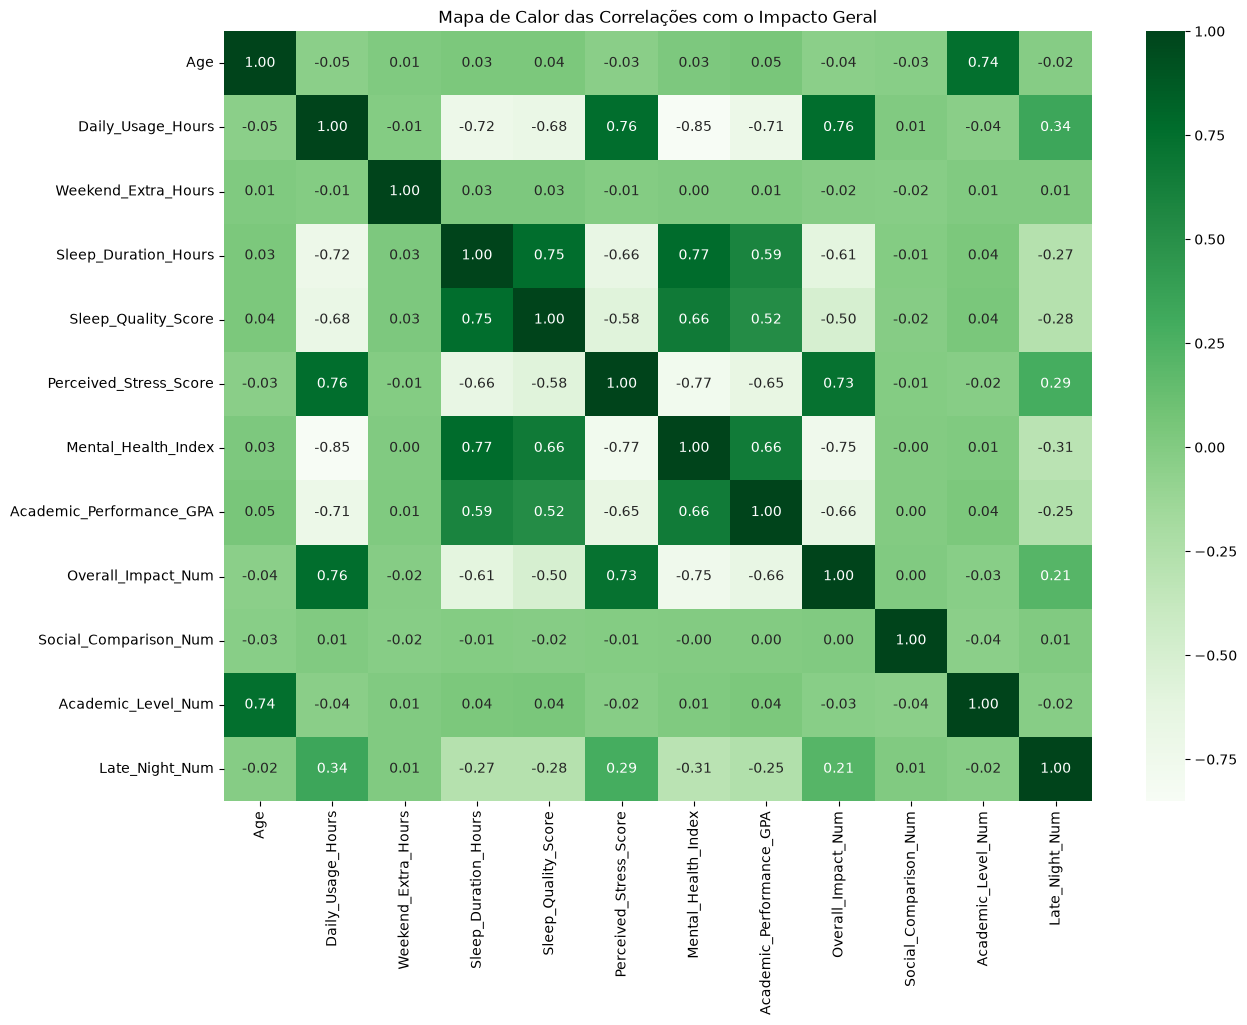

In [4]:
df_corr = pd.concat([X_train, y_train], axis=1)

mapa_impacto = {"Beneficial": 0, "Neutral": 1, "Negative": 2}
mapa_comparacao = {"Never": 0, "Rarely": 1, "Sometimes": 2, "Frequently": 3, "Always": 4}
mapa_academico = {"High School": 0, "Undergraduate": 1, "Postgraduate": 2}

df_corr["Overall_Impact_Num"] = y_train.map(mapa_impacto)
df_corr["Social_Comparison_Num"] = df_corr["Social_Comparison_Frequency"].map(mapa_comparacao)
df_corr["Academic_Level_Num"] = df_corr["Academic_Level"].map(mapa_academico)
df_corr["Late_Night_Num"] = df_corr["Late_Night_Usage"].astype(int)

# Selecionar apenas colunas numéricas para a matriz de correlação
colunas_num_corr = df_corr.select_dtypes(include=[np.number]).columns
corr = df_corr[colunas_num_corr].corr()

plt.figure(figsize=(14, 10))
sns.heatmap(corr, cbar=True, fmt=".2f", annot=True, annot_kws={"size": 10}, cmap="Greens")
plt.title("Mapa de Calor das Correlações com o Impacto Geral")
plt.show()

As 6 variáveis de maior impacto

- **Horas de uso por dia** (Daily_Usage_Hours: +0.76): É a correlação positiva mais forte do dataset. Quanto maior o tempo diário nas redes sociais, maior a probabilidade de o impacto migrar de benéfico para neutro ou negativo.   

- **Índice de Saúde Mental** (Mental_Health_Index: -0.75):Quanto menor o índice de saúde mental do estudante, maior o impacto negativo registrado.   

- **Score de Estresse** (Perceived_Stress_Score: +0.73): Forte correlação positiva — níveis elevados de estresse percebido caminham diretamente junto com o impacto negativo.   

- **Performance Acadêmica** (Academic_Performance_GPA: -0.66): Forte correlação negativa — notas mais baixas estão fortemente associadas ao impacto negativo das redes sociais.   

- **Duração do Sono** (Sleep_Duration_Hours: -0.61) e **Qualidade do Sono** (Sleep_Quality_Score:-0.50): Correlação negativa expressiva, indicando que menos horas dormidas e pior qualidade de sono elevam o risco de impacto prejudicial. 


Percentual de impacto por rede social (Treino):


Overall_Impact,Beneficial,Neutral,Negative
Primary_Platform,,,
YouTube,83.39,12.54,4.06
Snapchat,80.48,15.62,3.90
TikTok,80.30,15.85,3.85
Instagram,82.32,14.00,3.67
Reddit,82.35,14.71,2.94
X (Twitter),86.11,11.81,2.08
LinkedIn,76.39,22.22,1.39


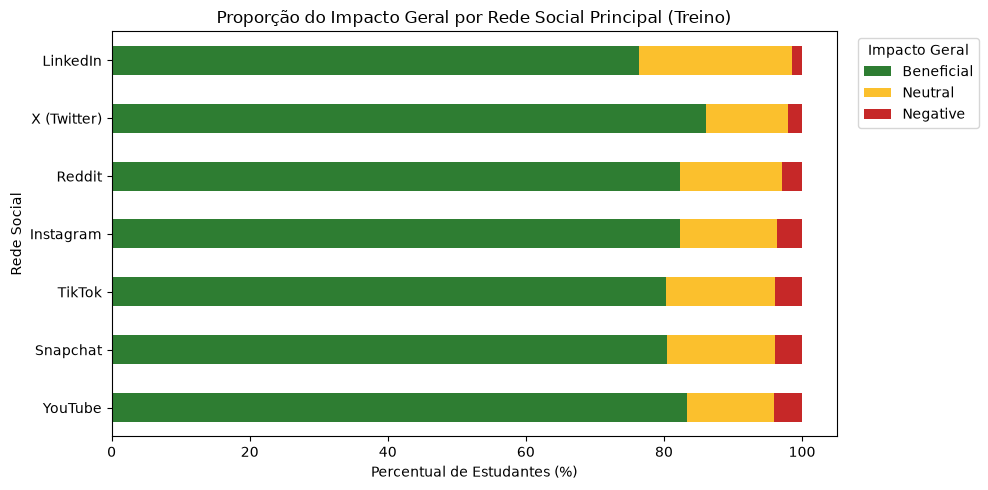

In [5]:
dt_plat = pd.DataFrame(
    {"Primary_Platform": X_train["Primary_Platform"],
    "Overall_Impact": y_train
})

# Calcular a proporção (%) de cada impacto DENTRO de cada rede social
tabela_proporcao = pd.crosstab(
    dt_plat["Primary_Platform"], 
    dt_plat["Overall_Impact"], 
    normalize="index"
) * 100

tabela_proporcao = tabela_proporcao[["Beneficial", "Neutral", "Negative"]].sort_values(
    by="Negative", ascending=False
)

print("Percentual de impacto por rede social (Treino):")
display(tabela_proporcao.round(2))

ax = tabela_proporcao.plot(
    kind="barh", 
    stacked=True, 
    figsize=(10, 5), 
    color=["#2e7d32", "#fbc02d", "#c62828"] # Verde, Amarelo, Vermelho
)
plt.title("Proporção do Impacto Geral por Rede Social Principal (Treino)")
plt.xlabel("Percentual de Estudantes (%)")
plt.ylabel("Rede Social")
plt.legend(title="Impacto Geral", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

**Features selecionadas (7 perguntas):** 

Mantemos as 6 variáveis numéricas de maior correlação (Daily_Usage_Hours, Mental_Health_Index, Perceived_Stress_Score, Academic_Performance_GPA, Sleep_Duration_Hours, Sleep_Quality_Score) e a variável categórica Primary_Platform (contendo exclusivamente as 7 redes originais do dataset: Instagram, TikTok, YouTube, Snapchat, Reddit, X (Twitter), LinkedIn).

Features descartadas: Removemos Student_ID (identificador) e as colunas com correlação próxima de zero (Age, Gender, Academic_Level, Device_Type, Weekend_Extra_Hours, Social_Comparison_Frequency e Late_Night_Usage) para evitar ruído no modelo e tornar o formulário mais simples para o usuário.

Tratamento de nulos e escalas: O mapa de missing values confirmou valores ausentes em Perceived_Stress_Score e Academic_Performance_GPA. Aplicaremos SimpleImputer(strategy="median") + StandardScaler() nas numéricas, e OneHotEncoder(handle_unknown="ignore") em Primary_Platform, tudo encapsulado em um ColumnTransformer.

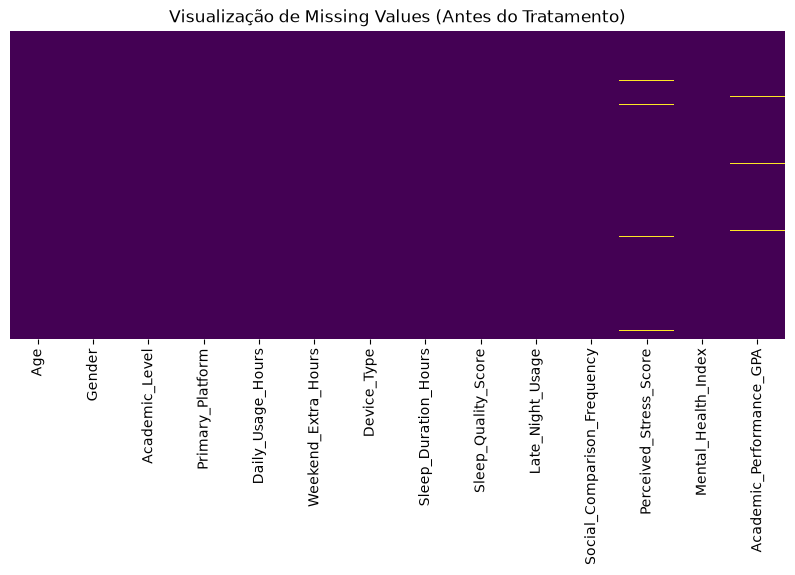

In [6]:
plt.figure(figsize=(10, 4))
sns.heatmap(X_train.isna(), cbar=False, yticklabels=False, cmap="viridis")
plt.title("Visualização de Missing Values (Antes do Tratamento)")
plt.show()

In [7]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder # Transformam números de escalas diferentes e textos em formatos que a matemática dos algoritmos entende.
from sklearn.dummy import DummyClassifier # usado apenas como régua de comparação (Baseline).
from sklearn.model_selection import StratifiedKFold, cross_val_score # Fazem a validação cruzada dividindo os dados em 5 partes proporcionais para testar a estabilidade do modelo.


# Seleção das colunas numéricas e categóricas
colunas_numericas = [
    "Daily_Usage_Hours",
    "Mental_Health_Index",
    "Perceived_Stress_Score",
    "Academic_Performance_GPA",
    "Sleep_Duration_Hours",
    "Sleep_Quality_Score"
]

colunas_categoricas = ["Primary_Platform"]

# Tratamento específico por tipo de dado
pipe_num = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
# Calcula a mediana de cada coluna (usando só os dados de treino) e preenche os buracos.


pipe_cat = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])


preprocessador = ColumnTransformer(
    transformers=[
        ("num", pipe_num, colunas_numericas),
        ("cat", pipe_cat, colunas_categoricas)
    ],
    remainder="drop" # Qualquer outra coluna que estiver sobrando na tabela deve ser descartada automaticamente
)


pipe_baseline = Pipeline(steps=[
    ("preprocessamento", preprocessador),
    ("modelo", DummyClassifier(strategy="most_frequent"))
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
# Divide o X_train em 5 pedaços iguais mantendo a mesma proporção de alunos Beneficial (81,8%), Neutral (14,5%) e Negative (3,7%) em cada pedaço. Ele treina em 4 pedaços e valida no 5º, repetindo isso 5 vezes.

scores_base = cross_val_score(pipe_baseline, X_train, y_train, cv=cv, scoring="f1_macro")
print(f"F1-Macro Baseline (CV): {scores_base.mean():.4f} (+/- {scores_base.std():.4f})")

# Conclusão para o projeto: Qualquer algoritmo precisa bater 0.3000 com folga de 0.0002 para provar que realmente aprendeu padrões úteis.

F1-Macro Baseline (CV): 0.3000 (+/- 0.0002)
